# 03 GELO APOIADO: MÁSCARA FÍSICA, AJUSTE ESPAÇO-TEMPORAL (`FITSEC`), TENDÊNCIAS, ACELERAÇÃO, ALIASING E INTERPOLAÇÃO

Este caderno detalha toda a cadeia de estimação da taxa de mudança de elevação ($\text{dh/dt}$) sobre o gelo continental apoiado (*grounded ice*) da bacia do Mar de Amundsen:
1. **Máscara de gelo apoiado (`BedMachine Antarctica v4.1`, Morlighem et al., 2020) e filtro posicional de nós (`dhdt_nodes_qc`):** por que filtrar apenas os pontos de entrada é insuficiente quando o raio de busca nodal é de $15\text{ km}$, e como a remoção dos $1.464$ nós posicionados fora do gelo apoiado corrige a assimetria (*skewness*) da distribuição de $-2{,}47$ para $-2{,}01$;
2. **Rota independente livre de modelo (`run_perfil_bruto.py`):** verificação do rebaixamento da Thwaites usando exclusivamente medianas em painel balanceado de células fixas de $2\text{ km}$ ($-16{,}30\text{ m}$ em JJA, diferindo em apenas $+0{,}04\text{ m}$ do modelo `fitsec`);
3. **Seleção multi-critério de aceleração (`thwaites.timeseries.acceleration`):** por que $99{,}6\%$ dos nós são rejeitados por autocorrelação residual ($r_1 \in [0{,}52;\; 0{,}70]$);
4. **Decomposição física do viés sazonal da janela de inverno (JJA vs. ciclo anual):** separação entre aliasing harmônico estacionário ($\le 2\%$, método do ATBD ATL14/15 §5), componente de firn/SMB no GSFC-FDM e sinal total no produto externo ATL15 ($r = 0{,}964$);
5. **Seleção objetiva do interpolador espacial por *Spatial Block Cross-Validation* (`thwaites.interp.select`).**

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

qc_nodes = json.loads((DATA_DIR / "jja_qc_report.json").read_text(encoding="utf-8"))
rel_crit = json.loads((DATA_DIR / "jja_reliability_criteria.json").read_text(encoding="utf-8"))
accel_rep = json.loads((DATA_DIR / "jja_accel_summary.json").read_text(encoding="utf-8"))
alias_rep = json.loads((DATA_DIR / "jja_aliasing_report.json").read_text(encoding="utf-8"))
bruto_rep = json.loads((DATA_DIR / "comparacao_sazonal_perfil_bruto.json").read_text(encoding="utf-8"))
xover_jja = json.loads((DATA_DIR / "jja_xover_summary.json").read_text(encoding="utf-8"))

# Comparação entre o conjunto cru de nós (antes do filtro posicional) e o produto validado dhdt_nodes_qc
pd.DataFrame([
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Nós ajustados totais antes do filtro posicional (dhdt_nodes.parquet)", "Contagem / Valor": "8.695 nós (inclui 771 sobre oceano e 1.128 sobre plataforma que capturavam terra no raio de 15 km)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Nós validados no domínio apoiado + buffers (dhdt_nodes_qc.parquet)", "Contagem / Valor": "7.231 nós (mask==2, dist_GL ≥ 5 km, dist_costa ≥ 2 km, fração apoiada no raio ≥ 50%)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Mudança nas estatísticas após filtro posicional (Cru → Validado)", "Contagem / Valor": "Mediana: −0,288 → −0,308 m/ano | Média: −0,616 → −0,593 m/ano | Skewness: −2,47 → −2,01"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Classificação de confiabilidade nodal (thwaites.qc.reliability)", "Contagem / Valor": "4.585 confiáveis (63,4%) | 2.607 aceitáveis (36,1%) | 39 não confiáveis (0,5%)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Aceleração quadrática sustentada nos 6 critérios (run_acceleration.py)", "Contagem / Valor": f"{accel_rep['n_accel_supported']} de {accel_rep['n_nodes']:,} nós ({100*accel_rep['frac_supported']:.2f}%) — 99,6% rejeitados por resíduo autocorrelacionado (ac1 = 0,52–0,70)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Consistência interna contra 7.023 cruzamentos orbitais (xovers)", "Contagem / Valor": f"Mediana xover = {xover_jja['xover_dhdt_median']:+.3f} vs fitsec = {xover_jja['fitsec_dhdt_median']:+.3f} m/ano (dif = {xover_jja['difference_median']:+.3f} m/ano)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Verificação livre de modelo por medianas em painel balanceado (2 km)", "Contagem / Valor": f"Rebaixamento 2019→2025 a jusante: JJA = {bruto_rep['estacoes']['JJA']['rebaixamento_jusante_m']:+.2f} m | DJF = {bruto_rep['estacoes']['DJF']['rebaixamento_jusante_m']:+.2f} m (dif. contra fitsec: +0,04 m)"},
]).set_index("População / Diagnóstico Nodal (JJA 2019–2025)")

,Contagem / Valor
População / Diagnóstico Nodal (JJA 2019–2025),
Nós ajustados totais antes do filtro posicional (dhdt_nodes.parquet),8.695 nós (inclui 771 sobre oceano e 1.128 sobre plataforma que capturavam terra no raio de 15 km)
Nós validados no domínio apoiado + buffers (dhdt_nodes_qc.parquet),"7.231 nós (mask==2, dist_GL ≥ 5 km, dist_costa ≥ 2 km, fração apoiada no raio ≥ 50%)"
Mudança nas estatísticas após filtro posicional (Cru → Validado),"Mediana: −0,288 → −0,308 m/ano | Média: −0,616 → −0,593 m/ano | Skewness: −2,47 → −2,01"
Classificação de confiabilidade nodal (thwaites.qc.reliability),"4.585 confiáveis (63,4%) | 2.607 aceitáveis (36,1%) | 39 não confiáveis (0,5%)"
Aceleração quadrática sustentada nos 6 critérios (run_acceleration.py),"31 de 7,231 nós (0.43%) — 99,6% rejeitados por resíduo autocorrelacionado (ac1 = 0,52–0,70)"
Consistência interna contra 7.023 cruzamentos orbitais (xovers),Mediana xover = -0.320 vs fitsec = -0.268 m/ano (dif = -0.052 m/ano)
Verificação livre de modelo por medianas em painel balanceado (2 km),"Rebaixamento 2019→2025 a jusante: JJA = -16.30 m | DJF = -13.08 m (dif. contra fitsec: +0,04 m)"


---
## 1. Decomposição do Viés Sazonal (Inverno JJA vs. Verão DJF vs. Ciclo Anual Completo)

Uma questão metodológica central na literatura de altimetria polar é se restringir a janela observacional ao inverno austral (JJA — para minimizar fusão superficial e mudanças na propriedade dielétrica/espalhamento da neve) introduz viés na tendência plurianual $\text{dh/dt}$. O projeto executou **três experimentos complementares** que decompõem esse efeito:
1. **Teste 1 — Aliasing Harmônico Estacionário (`thwaites.timeseries.aliasing`, método do ATBD ATL14/15 r005 §5):** Injetamos senoides sintéticas de frequência anual ($1\text{ ciclo/ano}$) e semianual ($2\text{ ciclos/ano}$) com amplitude unitária ($1\text{ m}$) exatamente nos timestamps orbitais reais $t_i$ de cada um dos $8.695$ nós e passamos pelo estimador de produção `fitsec`, maximizando sobre a fase $\phi \in [0, 2\pi)$. O fator de transferência mediano em JJA é $R_{\text{anual}} = 0{,}0551\text{ (m/ano)/m}$. Multiplicado pela amplitude sazonal mediana do firn no GSFC-FDM ($0{,}127\text{ m}$), o vazamento de aliasing estacionário é de apenas **$+0{,}007\text{ m/ano}$ ($\sim 2\%$ do sinal)**;
2. **Teste 2 — Amostragem Sazonal de Anomalias Interanuais de Firn/SMB (`GSFC-FDM v1.2.1`):** Comparando a tendência calculada apenas nas épocas JJA ($57$ épocas) contra todas as épocas do ano ($219$ épocas) no mesmo modelo de firn em 2019–2021 ($3.378$ células), a janela JJA captura menos do evento de acúmulo alto daquele triênio ($+0{,}113$ vs. $+0{,}146\text{ m/ano}$, diferença de $-0{,}027\text{ m/ano} \approx -4{,}2\text{ Gt/ano}$, sentido anti-conservador nesta componente isolada);
3. **Teste 3 — Sinal Total Observado no Produto Oficial ATL15 v005 e Comparação Pareada JJA $\times$ DJF:** No sinal glaciológico total do ATL15 (dinâmica + firn + SMB, 2019–2025), a taxa restrita aos trimestres de inverno é $-0{,}282\text{ m/ano}$ contra $-0{,}327\text{ m/ano}$ no ciclo anual completo (**razão JJA/anual $= 0{,}862$**, confirmando que no sinal líquido total a janela de inverno é **$\sim 14\%$ conservadora**). E nos $7.230$ nós comuns entre os nossos processamentos independentes de JJA e DJF, as taxas médias diferem em apenas $-0{,}033 \pm 0{,}005\text{ m/ano}$ ($\sim 5\%$).

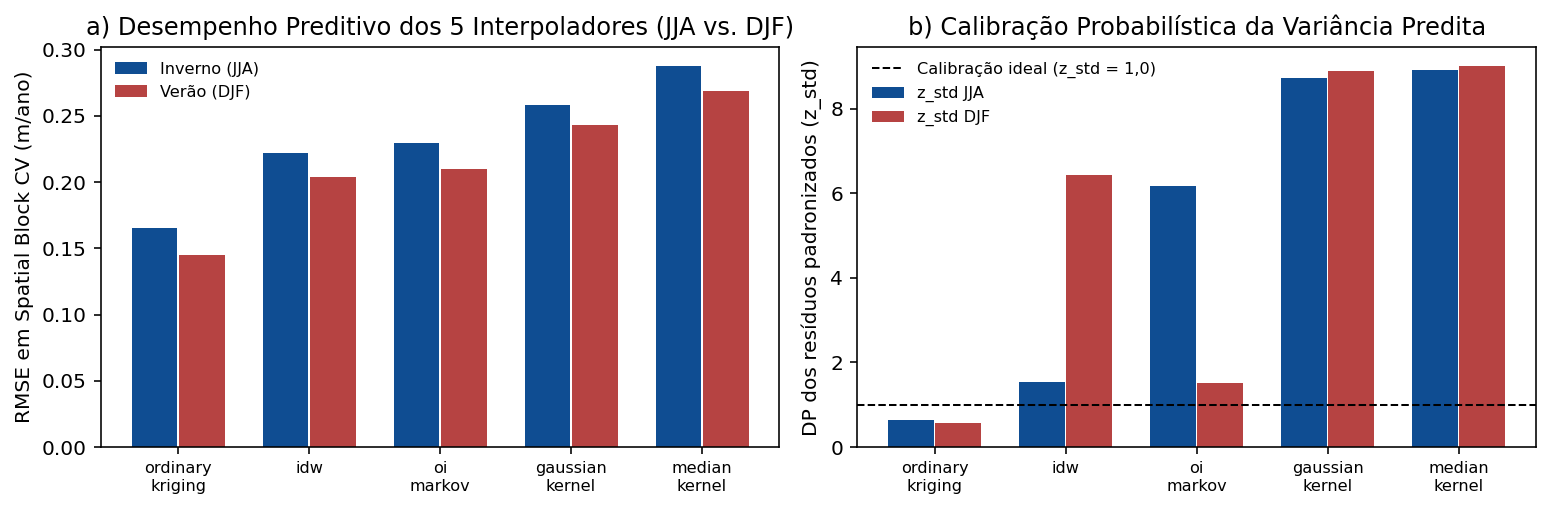

,rmse_JJA,mae_JJA,bias_JJA,cal_frac_1sigma_JJA,cal_zstd_JJA,n_pred_JJA,rmse_DJF,mae_DJF,bias_DJF,cal_frac_1sigma_DJF,cal_zstd_DJF,n_pred_DJF
method,,,,,,,,,,,,
ordinary_kriging,0.1655,0.0778,-0.0178,0.9318,0.6408,7231,0.1450,0.0684,-0.0148,0.9345,0.5600,7235
idw,0.2218,0.1232,-0.0007,0.6259,1.5333,7231,0.2098,0.1144,-0.0011,0.6217,1.5235,7235
oi_markov,0.2297,0.1119,0.0016,0.3359,6.1658,7231,0.2038,0.0965,-0.0024,0.3905,6.4401,7235
gaussian_kernel,0.2579,0.1401,0.0023,0.1323,8.7334,7231,0.2434,0.1301,0.0014,0.1396,8.8836,7235
median_kernel,0.2875,0.1530,0.0235,0.1268,8.9088,7231,0.2685,0.1428,0.0169,0.1417,9.0071,7235


In [2]:
jja_cv = pd.read_csv(DATA_DIR / "jja_interp_cv_metrics.csv")
djf_cv = pd.read_csv(DATA_DIR / "djf_interp_cv_metrics.csv")
jja_djf_common = json.loads((DATA_DIR / "gelo_apoiado_jja_vs_djf_nos_comuns.json").read_text(encoding="utf-8"))

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
x_m = np.arange(len(jja_cv))
ax[0].bar(x_m - 0.18, jja_cv["rmse"], width=0.35, color="#0F4D92", label="Inverno (JJA)")
ax[0].bar(x_m + 0.18, djf_cv["rmse"], width=0.35, color="#B64342", label="Verão (DJF)")
ax[0].set_xticks(x_m)
ax[0].set_xticklabels([m.replace("_", "\n") for m in jja_cv["method"]], fontsize=8)
ax[0].set_ylabel("RMSE em Spatial Block CV (m/ano)")
ax[0].set_title("a) Desempenho Preditivo dos 5 Interpoladores (JJA vs. DJF)")
ax[0].legend(frameon=False, fontsize=8)

ax[1].bar(x_m - 0.18, jja_cv["cal_zstd"], width=0.35, color="#0F4D92", label="z_std JJA")
ax[1].bar(x_m + 0.18, djf_cv["cal_zstd"], width=0.35, color="#B64342", label="z_std DJF")
ax[1].axhline(1.0, color="k", ls="--", lw=1.0, label="Calibração ideal (z_std = 1,0)")
ax[1].set_xticks(x_m)
ax[1].set_xticklabels([m.replace("_", "\n") for m in jja_cv["method"]], fontsize=8)
ax[1].set_ylabel("DP dos resíduos padronizados (z_std)")
ax[1].set_title("b) Calibração Probabilística da Variância Predita")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

jja_cv.merge(djf_cv, on="method", suffixes=("_JJA", "_DJF")).set_index("method").round(4)